In [1]:
import pandas as pd 

In [2]:
import numpy as np

In [3]:
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder

In [5]:
df=pd.read_csv("C:/Users/viswath/Downloads/crop_yield.csv (1).xls")

In [6]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [7]:
df.tail()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
19684,Small millets,1998,Kharif,Nagaland,4000.0,2000,1498.0,395200.00,1160.00,0.500000
19685,Wheat,1998,Rabi,Nagaland,1000.0,3000,1498.0,98800.00,290.00,3.000000
19686,Maize,1997,Kharif,Jammu and Kashmir,310883.0,440900,1356.2,29586735.11,96373.73,1.285000
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,5488,1356.2,26242746.82,85481.26,0.016667
19688,Wheat,1997,Rabi,Jammu and Kashmir,239344.0,392160,1356.2,22778368.48,74196.64,1.261818


In [8]:
df.size

196890

In [9]:
df.columns

Index(['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production',
       'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield'],
      dtype='str')

In [10]:
df.dtypes

Crop                   str
Crop_Year            int64
Season                 str
State                  str
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64
dtype: object

In [11]:
df.isnull()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...
19684,False,False,False,False,False,False,False,False,False,False
19685,False,False,False,False,False,False,False,False,False,False
19686,False,False,False,False,False,False,False,False,False,False
19687,False,False,False,False,False,False,False,False,False,False


In [12]:
df.isnull().sum()

Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

In [13]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
19684    False
19685    False
19686    False
19687    False
19688    False
Length: 19689, dtype: bool

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.loc[1:5,["State","Crop_Year"]]

,State,Crop_Year
1,Assam,1997
2,Assam,1997
3,Assam,1997
4,Assam,1997
5,Assam,1997


In [16]:
df.iloc[0:2,0:8]

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29


In [17]:
df[(df["Crop_Year"])=="rabi"]

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield


In [18]:
df.groupby("Production")["Area"].min()

Production
0                  0.5
1                  1.0
2                  0.8
3                  1.0
4                  1.0
                ...   
5962500000    434875.0
6001000000    899267.0
6054000000    872943.0
6200900000    419400.0
6326000000    897833.0
Name: Area, Length: 14016, dtype: float64

In [19]:
from sklearn.preprocessing import OrdinalEncoder

# Leave categories out so it learns every unique crop in your data automatically
ordinal = OrdinalEncoder()

df["Crop2"] = ordinal.fit_transform(df[["Crop"]])
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Crop2
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,0.0
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,1.0
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,8.0
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,9.0
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,11.0


In [20]:
print(df.columns.tolist())

['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield', 'Crop2']


In [21]:
import pandas as pd

# Check if the column is present before encoding to prevent KeyError
if "State_Name" in df.columns:
    df = pd.get_dummies(df, columns=["State_Name"], dtype=int)
else:
    print("Notice: 'State_Name' is already encoded or missing. Skipping to prevent crash.")

# View the result
df.head()

Notice: 'State_Name' is already encoded or missing. Skipping to prevent crash.


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield,Crop2
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087,0.0
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435,1.0
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333,8.0
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739,9.0
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909,11.0


In [22]:
numeric_df=df.select_dtypes(include="number")
result=pd.DataFrame({
    "Mean":numeric_df.mean(),
    "Median":numeric_df.median(),
    "Mode":numeric_df.mode().iloc[0]
})
print(result.round(3))

                         Mean      Median      Mode
Crop_Year        2.009128e+03     2010.00  2019.000
Area             1.799266e+05     9317.00     1.000
Production       1.643594e+07    13804.00     0.000
Annual_Rainfall  1.437755e+03     1247.60  1434.588
Fertilizer       2.410331e+07  1234957.44   150.800
Pesticide        4.884835e+04     2421.90     0.990
Yield            7.995400e+01        1.03     1.000
Crop2            2.935800e+01       31.00    40.000


In [23]:
production1=pd.DataFrame({
    "Variance":numeric_df.var(),
    "Standard Deviation":numeric_df.std()
})
print(production1)

                     Variance  Standard Deviation
Crop_Year        4.222529e+01        6.498099e+00
Area             5.370379e+11        7.328287e+05
Production       6.919890e+16        2.630568e+08
Annual_Rainfall  6.673413e+05        8.169096e+02
Fertilizer       9.014744e+15        9.494600e+07
Pesticide        4.549150e+10        2.132874e+05
Yield            7.714218e+05        8.783062e+02
Crop2            2.421403e+02        1.556086e+01


In [24]:
production2=pd.DataFrame({
    "Minimum":numeric_df.min(),
    "Maximum":numeric_df.max(),
    "Range":numeric_df.max()-numeric_df.min()
})
print(production2.astype(int))

                 Minimum     Maximum       Range
Crop_Year           1997        2020          23
Area                   0    50808100    50808099
Production             0  6326000000  6326000000
Annual_Rainfall      301        6552        6251
Fertilizer            54  4835406877  4835406822
Pesticide              0    15750511    15750510
Yield                  0       21105       21105
Crop2                  0          54          54


In [25]:
production3 = pd.DataFrame({
    "Q1(25%)": numeric_df.quantile(0.25),
    "Q2(Median)": numeric_df.quantile(0.50),
    "Q3(75%)": numeric_df.quantile(0.75),
})

In [26]:
production3["IQR"] = production3["Q3(75%)"] - production3["Q1(25%)"]

print(production3)

                   Q1(25%)  Q2(Median)       Q3(75%)           IQR
Crop_Year          2004.00     2010.00  2.015000e+03  1.100000e+01
Area               1390.00     9317.00  7.511200e+04  7.372200e+04
Production         1393.00    13804.00  1.227180e+05  1.213250e+05
Annual_Rainfall     940.70     1247.60  1.643700e+03  7.030000e+02
Fertilizer       188014.62  1234957.44  1.000385e+07  9.815833e+06
Pesticide           356.70     2421.90  2.004170e+04  1.968500e+04
Yield                 0.60        1.03  2.388889e+00  1.788889e+00
Crop2                17.00       31.00  4.300000e+01  2.600000e+01


In [27]:
production4=pd.DataFrame({
    "Skewness":numeric_df.skew()
})
print(production4.round(3))

                 Skewness
Crop_Year          -0.163
Area               21.858
Production         19.299
Annual_Rainfall     2.132
Fertilizer         13.413
Pesticide          25.636
Yield              12.785
Crop2              -0.222


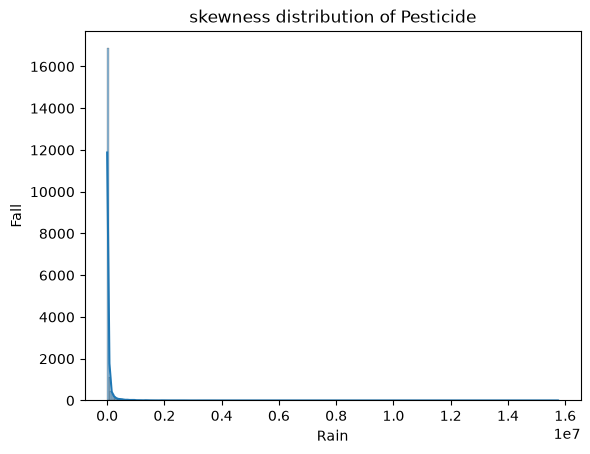

skewness: 25.635746086843607


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns 
column = numeric_df.columns[5]


sns.histplot(numeric_df[column],kde=True)

plt.title(f"skewness distribution of {column}")
plt.xlabel("Rain")
plt.ylabel("Fall")
plt.show()

print("skewness:",numeric_df[column].skew())

In [29]:
production5=pd.DataFrame({
    "kurtosis":numeric_df.kurt()
})

print(production5.round(3))

                 kurtosis
Crop_Year          -1.172
Area             1202.625
Production        388.567
Annual_Rainfall     6.975
Fertilizer        408.454
Pesticide        1546.728
Yield             175.577
Crop2              -1.118


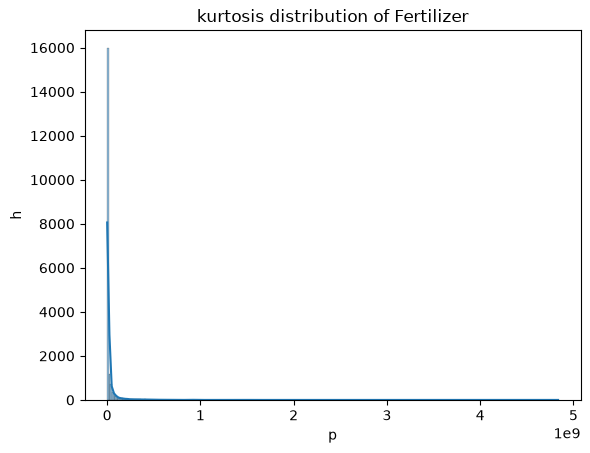

kurtosis: 408.4541019821852


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns 
column = numeric_df.columns[4]


sns.histplot(numeric_df[column],kde=True)

plt.title(f"kurtosis distribution of {column}")
plt.xlabel("p")
plt.ylabel("h")
plt.show()

print("kurtosis:",numeric_df[column].kurt())

In [31]:
mean_values=numeric_df.mean()
std_values=numeric_df.std()

production6=pd.DataFrame({
    "Mean":mean_values,
    "Standard Deviation":std_values,
    "CV(%)":(std_values/mean_values)*100
})
print(production6.round(3))

                         Mean  Standard Deviation     CV(%)
Crop_Year        2.009128e+03        6.498000e+00     0.323
Area             1.799266e+05        7.328287e+05   407.293
Production       1.643594e+07        2.630568e+08  1600.498
Annual_Rainfall  1.437755e+03        8.169100e+02    56.818
Fertilizer       2.410331e+07        9.494600e+07   393.913
Pesticide        4.884835e+04        2.132874e+05   436.632
Yield            7.995400e+01        8.783060e+02  1098.514
Crop2            2.935800e+01        1.556100e+01    53.004


In [32]:
Q1=numeric_df.quantile(0.25)
Q3=numeric_df.quantile(0.75)

IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR

outliers=(
    (numeric_df<lower_limit)|
    (numeric_df>upper_limit)
)
print("Lower Bound:\n",lower_limit)
print("Upper Bound:\n",upper_limit)
print("outliers in each column:\n",numeric_df[outliers].count())

Lower Bound:
 Crop_Year          1.987500e+03
Area              -1.091930e+05
Production        -1.805945e+05
Annual_Rainfall   -1.138000e+02
Fertilizer        -1.453573e+07
Pesticide         -2.917080e+04
Yield             -2.083333e+00
Crop2             -2.200000e+01
dtype: float64
Upper Bound:
 Crop_Year          2.031500e+03
Area               1.856950e+05
Production         3.047055e+05
Annual_Rainfall    2.698200e+03
Fertilizer         2.472760e+07
Pesticide          4.956920e+04
Yield              5.072222e+00
Crop2              8.200000e+01
dtype: float64
outliers in each column:
 Crop_Year             0
Area               3076
Production         3373
Annual_Rainfall    1527
Fertilizer         3093
Pesticide          3036
Yield              3065
Crop2                 0
dtype: int64
